# Supply and demand in the populist vote: East vs West Germany

The populism literature splits explanations into **demand** (voter grievances — what the ESS
trust items measure) and **supply** (whether a credible populist vehicle exists, and how well
it converts grievance into votes). Mudde's argument is that demand is widespread and fairly
constant, so supply does the explanatory work; Golder adds that the relation is *conditional* —
supply governs how much demand is translated into votes.

The standard way to separate them is two-way fixed effects, with a national year effect standing
in for supply:

```
logit(vote[r,t]) = c0 + alpha[r] + delta[t] + beta * trust[r,t]
```

- `delta[t]` — the national common component each election year. The **supply** term.
- `alpha[r]` — the time-invariant East/West baseline difference.
- `beta` — the **demand** effect: does trust move the vote, net of the other two?

## Why this notebook fits all three explicitly

An earlier version of this notebook pre-reduced the algebra. With two regions, differencing
across East and West cancels `delta[t]` exactly, and the intercept absorbs `alpha[r]`, leaving
`Δlogit(vote)[t] = c + beta·Δtrust[t]` — two parameters, seven points. The algebra is right
(Frisch-Waugh-Lovell: with two groups, the two-way FE `beta` equals the slope from regressing
the time-demeaned group difference of y on that of x), and it is genuinely the most economical
way to get `beta`.

But it means `alpha` and `delta` were **eliminated before the model was ever written down** —
they existed only as a numpy mean plotted on the side, with no uncertainty and no connection to
the fit. A supply/demand decomposition whose supply term never enters the model is a
trust-only regression wearing a label. So this version fits the full specification: same
`beta` (checked below, not assumed), but `alpha` and `delta` are now real posteriors that can
be read and doubted.

## What it can and cannot deliver

`beta` is expected to be wide and sign-ambiguous: after both fixed effects the predictor varies
by only ~0.17 trust points on a 0–10 scale, across 7 points, one of which (2002) carries extreme
leverage. That is measured explicitly before fitting rather than discovered afterwards.

And `delta[t]` remains interpretively limited even now that it is fitted. With two regions it is
pinned by the cross-region mean each year, so it absorbs *everything* national — COVID, the
refugee crisis, campaign events — not supply alone. Fitting it makes it honest and
uncertainty-quantified; it does not make it a measurement of party supply.

The concrete purpose is **diagnostic**: `trust_populism_de_east_west.ipynb` found significantly
*positive* within-region level slopes (+1.94 pre-2015, +2.39 post-2015). If those collapse once
`delta[t]` absorbs the national trend, they were co-trending artefacts.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt
import arviz as az

REP_ITEMS = ["trstprl", "trstplt", "trstprt"]
IMP_ITEMS = ["trstlgl", "trstplc"]
N_CAT = 11
REGIONS = ["West", "East"]           # East is index 1; gaps are East - West
REGION_COLORS = {"West": "#1f77b4", "East": "#d62728"}

ROUND_YEARS = {1: 2002, 2: 2004, 3: 2006, 4: 2008, 5: 2010, 6: 2012,
               7: 2014, 8: 2016, 9: 2018, 10: 2020, 11: 2023}
ELECTION_ROUND = {2002: 1, 2005: 2, 2009: 4, 2013: 6, 2017: 8, 2021: 10, 2025: 11}
ELECTIONS = sorted(ELECTION_ROUND)

REGIONDE_LABELS = {
    1: "Schleswig-Holstein", 2: "Hamburg", 3: "Niedersachsen", 4: "Bremen",
    5: "Nordrhein-Westfalen", 6: "Hessen", 7: "Rheinland-Pfalz",
    8: "Baden-Wuerttemberg", 9: "Bayern", 10: "Saarland", 11: "Berlin",
    12: "Brandenburg", 13: "Mecklenburg-Vorpommern", 14: "Sachsen",
    15: "Sachsen-Anhalt", 16: "Thueringen"}
NUTS1_LABELS = {
    "DE1": "Baden-Wuerttemberg", "DE2": "Bayern", "DE3": "Berlin", "DE4": "Brandenburg",
    "DE5": "Bremen", "DE6": "Hamburg", "DE7": "Hessen",
    "DE8": "Mecklenburg-Vorpommern", "DE9": "Niedersachsen",
    "DEA": "Nordrhein-Westfalen", "DEB": "Rheinland-Pfalz", "DEC": "Saarland",
    "DED": "Sachsen", "DEE": "Sachsen-Anhalt", "DEF": "Schleswig-Holstein",
    "DEG": "Thueringen"}
EAST_LAENDER = {"Brandenburg", "Mecklenburg-Vorpommern", "Sachsen",
                "Sachsen-Anhalt", "Thueringen"}

df = pd.read_csv("../literature/ESS_Dataset/Datafile-subset.csv", low_memory=False)
de = df[df["cntry"] == "DE"].copy()
de["essround"] = de["essround"].astype(int)
for col in REP_ITEMS + IMP_ITEMS:
    de[col] = pd.to_numeric(de[col], errors="coerce")
    de.loc[de[col].isin([77, 88, 99]), col] = np.nan
de["land"] = de["region"].map(NUTS1_LABELS).fillna(de["regionde"].map(REGIONDE_LABELS))
de["ew"] = np.where(de["land"].isin(EAST_LAENDER), "East",
                    np.where(de["land"] == "Berlin", "Berlin", "West"))
ess = de[de["ew"].isin(REGIONS)].copy()          # Berlin excluded throughout

ROUNDS = sorted(ess["essround"].unique())
T = len(ROUNDS)
years = np.array([ROUND_YEARS[r] for r in ROUNDS])
dt = np.diff(years).astype(float)
n_regions = len(REGIONS)
t_of_election = np.array([ROUNDS.index(ELECTION_ROUND[y]) for y in ELECTIONS])
print(f"ESS respondents (Berlin excluded): {len(ess):,}  |  rounds {T}  |  elections {len(ELECTIONS)}")

ESS respondents (Berlin excluded): 35,081  |  rounds 11  |  elections 7


## Why cutpoints can be shared between East and West

The gap estimand requires that one unit of latent trust mean the same thing in both regions.
Region-specific cutpoints (used in `trust_populism_de_east_west.ipynb`, deliberately, to make
cross-region comparison impossible) would not guarantee that.

Whether sharing is defensible is testable: under a pure latent shift with common cutpoints, the
implied East−West shift should be **constant across the 10 response thresholds**. The same check
for Germany vs France gave sds of 0.15–0.23 and clearly failed.

In [2]:
def logit(p):
    return np.log(p / (1 - p))


print("implied East-West latent shift at each threshold k (constant => sharing is safe)\n")
for item in REP_ITEMS + IMP_ITEMS:
    w = ess.loc[ess.ew == "West", item].dropna()
    e = ess.loc[ess.ew == "East", item].dropna()
    sh = []
    for k in range(10):
        pW, pE = (w <= k).mean(), (e <= k).mean()
        sh.append(np.nan if min(pW, pE) <= 0.01 or max(pW, pE) >= 0.99
                  else logit(pE) - logit(pW))
    s = np.array(sh, dtype=float)
    block = "rep" if item in REP_ITEMS else "imp"
    print(f"{item} ({block}): " + " ".join(f"{v:5.2f}" for v in s)
          + f"   mean {np.nanmean(s):5.2f}   sd {np.nanstd(s):.2f}")

print("\nReference: the same test for Germany vs France gave sd 0.15-0.23 and failed.")
print("  representative items: sd 0.05-0.06  -> invariance holds well, sharing well justified")
print("  implementing items:   sd 0.09-0.11  -> weaker, about half the DE/FR failure level.")
print("The headline analysis uses representative trust, where the case is strongest; the")
print("implementing run is a discriminant check and its shared-cutpoint assumption is the")
print("more strained of the two.")

implied East-West latent shift at each threshold k (constant => sharing is safe)

trstprl (rep):  0.76  0.72  0.68  0.62  0.59  0.66  0.64  0.65  0.74  0.67   mean  0.67   sd 0.05
trstplt (rep):  0.54  0.47  0.43  0.42  0.35  0.46  0.41  0.45   nan   nan   mean  0.44   sd 0.05
trstprt (rep):  0.60  0.53  0.48  0.45  0.42  0.52  0.48  0.40   nan   nan   mean  0.48   sd 0.06
trstlgl (imp):  0.83  0.81  0.74  0.73  0.66  0.72  0.68  0.64  0.68  0.50   mean  0.70   sd 0.09
trstplc (imp):  0.77  0.71  0.57  0.53  0.53  0.61  0.56  0.50  0.51  0.38   mean  0.57   sd 0.11

Reference: the same test for Germany vs France gave sd 0.15-0.23 and failed.
  representative items: sd 0.05-0.06  -> invariance holds well, sharing well justified
  implementing items:   sd 0.09-0.11  -> weaker, about half the DE/FR failure level.
The headline analysis uses representative trust, where the case is strongest; the
implementing run is a discriminant check and its shared-cutpoint assumption is the
more strained

In [3]:
# Actual election results, East/West aggregates (Berlin excluded).
vl = pd.read_csv("populist_vote_de_nuts1.csv")
vl["ew"] = np.where(vl["regionname"].isin(EAST_LAENDER | {"Thüringen"}), "East",
                    np.where(vl["regionname"] == "Berlin", "Berlin", "West"))
votes = (vl[vl["ew"].isin(REGIONS)]
         .groupby(["year", "ew"], as_index=False)[["populist_votes", "validvote"]].sum())
votes = votes[votes["year"].isin(ELECTIONS)]
votes["share"] = votes["populist_votes"] / votes["validvote"]
votes["logit"] = logit(votes["share"])

vw = votes.pivot(index="year", columns="ew", values="logit")[REGIONS]
obs_logit_full = vw.to_numpy().T        # (region, election) -- what the model fits
d_obs = (vw["East"] - vw["West"]).to_numpy()   # the gap, used for the feasibility table
naive_delta = vw.mean(axis=1).to_numpy()       # cross-region mean: the NAIVE supply proxy

print("populist vote share (%):")
print((votes.pivot(index="year", columns="ew", values="share")[REGIONS] * 100)
      .round(1).to_string())
print(f"\nobs_logit_full {obs_logit_full.shape} (region x election) -- the 14 fitted points")
print("\nEast-West gap in logits:")
print(pd.Series(d_obs, index=ELECTIONS).round(3).to_string())

populist vote share (%):
ew    West  East
year            
2002   1.3  16.5
2005   5.2  24.9
2009   8.4  28.0
2013   9.9  27.9
2017  17.9  39.5
2021  11.8  31.3
2025  29.5  58.0

obs_logit_full (2, 7) (region x election) -- the 14 fitted points

East-West gap in logits:
2002    2.696
2005    1.809
2009    1.439
2013    1.262
2017    1.099
2021    1.223
2025    1.193


## Feasibility, measured before fitting

Both fixed effects removed, what variation is left to identify `beta`?

In [4]:
def wmean(g, col):
    s = g[[col, "pspwght"]].dropna()
    return np.average(s[col], weights=s["pspwght"]) if len(s) else np.nan


ess["rep_score"] = ess[REP_ITEMS].mean(axis=1)
raw_gap = []
for y in ELECTIONS:
    g = ess[ess["essround"] == ELECTION_ROUND[y]]
    raw_gap.append(wmean(g[g.ew == "East"], "rep_score") - wmean(g[g.ew == "West"], "rep_score"))
raw_gap = np.array(raw_gap)

feas = pd.DataFrame({"year": ELECTIONS, "trust_gap": raw_gap, "vote_gap_logit": d_obs})
feas["trust_gap_dem"] = feas["trust_gap"] - feas["trust_gap"].mean()
feas["vote_gap_dem"] = feas["vote_gap_logit"] - feas["vote_gap_logit"].mean()
print(feas.round(3).to_string(index=False))
print(f"\nsd of demeaned trust gap (the predictor): {feas.trust_gap_dem.std():.3f} trust points")
print(f"sd of demeaned vote gap  (the outcome)  : {feas.vote_gap_dem.std():.3f} logits")
print(f"raw correlation: {feas.trust_gap_dem.corr(feas.vote_gap_dem):+.3f}   "
      f"OLS slope: {np.polyfit(feas.trust_gap_dem, feas.vote_gap_dem, 1)[0]:+.2f}")
print("\n2002 is an extreme leverage point (West populist share was 1.3%, so its logit is far")
print("from the rest) -- refit without it at the end.")

 year  trust_gap  vote_gap_logit  trust_gap_dem  vote_gap_dem
 2002     -0.615           2.696         -0.041         1.164
 2005     -0.338           1.809          0.235         0.278
 2009     -0.451           1.439          0.122        -0.093
 2013     -0.557           1.262          0.016        -0.270
 2017     -0.717           1.099         -0.144        -0.433
 2021     -0.502           1.223          0.071        -0.308
 2025     -0.832           1.193         -0.259        -0.339

sd of demeaned trust gap (the predictor): 0.166 trust points
sd of demeaned vote gap  (the outcome)  : 0.564 logits
raw correlation: +0.231   OLS slope: +0.79

2002 is an extreme leverage point (West populist share was 1.3%, so its logit is far
from the rest) -- refit without it at the end.


In [5]:
anchor = np.arange(10) - 4.5


def count_tensor(items):
    """counts[region, item, round, category]."""
    out = np.zeros((n_regions, len(items), T, N_CAT), dtype=int)
    for ri, reg in enumerate(REGIONS):
        sub = ess[ess["ew"] == reg]
        for ji, item in enumerate(items):
            for ti, rnd in enumerate(ROUNDS):
                vals = sub.loc[sub["essround"] == rnd, item].dropna().astype(int)
                if len(vals):
                    out[ri, ji, ti] = np.bincount(vals, minlength=N_CAT)
    return out


def ordered_probs(eta, cut):
    cdf = pm.math.sigmoid(cut[None, :] - eta[:, None])
    cdf = pt.concatenate([cdf, pt.ones((eta.shape[0], 1))], axis=1)
    prev = pt.concatenate([pt.zeros((eta.shape[0], 1)), cdf[:, :-1]], axis=1)
    return cdf - prev


def expected_score(eta, cut):
    """numpy version, for the raw-scale verification."""
    cdf = 1 / (1 + np.exp(-(cut[None, :] - eta[:, None])))
    cdf = np.concatenate([cdf, np.ones((eta.shape[0], 1))], axis=1)
    prev = np.concatenate([np.zeros((eta.shape[0], 1)), cdf[:, :-1]], axis=1)
    return (cdf - prev) @ np.arange(N_CAT)


counts = {"rep": count_tensor(REP_ITEMS), "imp": count_tensor(IMP_ITEMS)}
ITEMS = {"rep": REP_ITEMS, "imp": IMP_ITEMS}
print({k: v.shape for k, v in counts.items()})

{'rep': (2, 3, 11, 11), 'imp': (2, 2, 11, 11)}


## The model

Trust measurement (aggregated response counts, Dirichlet-Multinomial overdispersion, per-region
random walk over the 11 ESS rounds) is carried over unchanged from the previous notebooks, with
one change: **cutpoints are shared across regions**, justified by the DIF check above and
required for `theta[East]` and `theta[West]` to be on one scale.

On top of it, the full two-way fixed-effects regression over all 14 `(region, election)` cells:

```
logit(vote[r,e]) = c0 + alpha[r] + delta[e] + beta * theta[r, t(e)]
```

**Identification.** `alpha` and `delta` need a location constraint — adding a constant to every
`alpha` and subtracting it from every `delta` leaves the fit unchanged, a genuinely flat
direction rather than a merely weak one. Both are therefore constrained to sum to zero via
explicit centring, so `c0` carries the overall level and `alpha`/`delta` are pure deviations.

**Joint fit.** The regression shares a model with the trust measurement so `beta` inherits the
trust posterior. Two-stage (point-estimate `theta`, then regress) would suffer regression
dilution: noise in the predictor attenuates the slope by an unknown amount. That is the only
reason this needs PyMC at all.

**Normal-on-logit, not Binomial.** These are complete vote counts for the whole electorate, not
samples. A Binomial with n in the millions asserts ~1e-4 precision and leaves the regression no
residual freedom — tried in the previous notebook, it produced slopes near 39, far outside
their own prior, and sampled 5× slower.

In [6]:
def fit(dim="rep", keep=None, reduced=False):
    """Trust submodel + vote regression, fitted jointly.

    dim      : 'rep' or 'imp'
    keep     : boolean mask over elections (None = all 7)
    reduced  : if True, fit the pre-reduced gap-on-gap form (alpha and delta cancelled
               by hand) instead of the full two-way FE model. Used for the equivalence
               check, and for the leverage check where it is better conditioned.
    """
    items, cnt = ITEMS[dim], counts[dim]
    k = np.ones(len(ELECTIONS), bool) if keep is None else np.asarray(keep)

    with pm.Model() as m:
        # ---------- trust measurement (unchanged) ----------
        conc = pm.Deterministic("conc", pt.exp(pm.Normal("log_conc", 6.0, 2.0)))
        sigma_innov = pm.HalfNormal("sigma_innov", 0.2, shape=n_regions)
        level0 = pm.Normal("level0", 0, 1, shape=n_regions)
        z = pm.Normal("z_innov", 0, 1, shape=(n_regions, T - 1))
        steps = z * sigma_innov[:, None] * np.sqrt(dt)[None, :]
        theta = pm.Deterministic("theta", pt.concatenate(
            [level0[:, None], level0[:, None] + pt.cumsum(steps, axis=1)], axis=1))

        # SHARED cutpoints -- one set for both regions (see the DIF check)
        cut = pm.Normal("cut", mu=anchor, sigma=1, shape=(len(items), 10),
                        transform=pm.distributions.transforms.ordered,
                        initval=np.broadcast_to(anchor, (len(items), 10)).copy())

        for j, item in enumerate(items):
            for r, reg in enumerate(REGIONS):
                c_ = cnt[r, j]
                tot = c_.sum(axis=1)
                ok = np.where(tot > 0)[0]      # drops trstprt in round 1 (not asked in 2002)
                pm.DirichletMultinomial(
                    f"{item}_{reg}", n=tot[ok],
                    a=conc * ordered_probs(theta[r][ok], cut[j]), observed=c_[ok])

        theta_e = theta[:, t_of_election]              # (region, election)
        beta = pm.Normal("beta", 0, 2)
        sigma = pm.HalfNormal("sigma", 1)

        if reduced:
            # gap on gap: alpha and delta cancelled by hand, so the national component is
            # removed EXACTLY rather than up to prior shrinkage.
            c = pm.Normal("c", 0, 2)
            pm.Normal("d_vote", mu=c + beta * (theta_e[1] - theta_e[0])[k],
                      sigma=sigma, observed=d_obs[k])
        else:
            # ---------- full two-way fixed effects ----------
            # alpha and delta are centred to sum to zero: without this, adding a constant
            # to every alpha and subtracting it from every delta leaves the fit unchanged.
            #
            # The prior on raw_delta is deliberately WIDE. delta exists to absorb the whole
            # national component so that beta is purged of it; a tight prior shrinks delta
            # toward zero, leaves part of the national trend unabsorbed, and lets it leak
            # into beta. (Checked: with sd=3 the fitted deltas came out ~40-60% of the
            # cross-region mean they should match, and beta drifted from +0.27 to +0.84
            # away from the exactly-differenced answer.)
            c0 = pm.Normal("c0", 0, 5)
            raw_alpha = pm.Normal("raw_alpha", 0, 5, shape=n_regions)
            alpha = pm.Deterministic("alpha", raw_alpha - raw_alpha.mean())
            raw_delta = pm.Normal("raw_delta", 0, 10, shape=int(k.sum()))
            delta = pm.Deterministic("delta", raw_delta - raw_delta.mean())

            eta = c0 + alpha[:, None] + delta[None, :] + beta * theta_e[:, k]
            pm.Normal("vote", mu=eta, sigma=sigma, observed=obs_logit_full[:, k])

        idata = pm.sample(1000, tune=1000, chains=4, cores=4,
                          target_accept=0.95, nuts_sampler="nutpie", progressbar=False)
    return idata


idata_rep = fit("rep")
print(az.summary(idata_rep,
                 var_names=["beta", "alpha", "delta", "c0", "sigma"]).to_string())
print(f"\ndivergences: {int(idata_rep.sample_stats['diverging'].sum())}")

NUTS[nutpie]: [log_conc, sigma_innov, level0, z_innov, cut, beta, sigma, c0, raw_alpha, raw_delta]


           mean    sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
beta        0.7  1.37     -1.4      2.9      630      932  1.00     0.055   0.033
alpha[0]  -0.93  0.35     -1.5    -0.38      774     1173  1.00     0.012  0.0074
alpha[1]   0.93  0.35     0.38      1.5      774     1173  1.00     0.012  0.0074
delta[0]  -1.27  0.41     -1.9    -0.62     1384     1874  1.00     0.011  0.0082
delta[1]  -0.21  0.57     -1.1     0.68      952     1346  1.00     0.018   0.013
delta[2]  -0.02  0.39    -0.63     0.58     1900     2230  1.00    0.0088  0.0088
delta[3]  -0.07  0.35     -0.6     0.47     4079     2463  1.00    0.0056   0.009
delta[4]   0.31   0.6    -0.65      1.3      930     1334  1.00      0.02   0.012
delta[5]   0.08  0.39     -0.5     0.67     2313     2132  1.00    0.0079   0.012
delta[6]   1.18  0.39     0.59      1.8     1884     1827  1.00    0.0089    0.01
c0         -0.8  1.44       -3      1.6      596      830  1.01     0.059   0.041
sigma      0.49 

In [7]:
# VERIFICATION: shared cutpoints must still reproduce the raw weighted means.
th = idata_rep.posterior["theta"].mean(("chain", "draw")).to_numpy()
cu = idata_rep.posterior["cut"].mean(("chain", "draw")).to_numpy()
implied = np.stack([np.mean([expected_score(th[r], cu[j]) for j in range(len(REP_ITEMS))],
                            axis=0) for r in range(n_regions)])
raw_mean = np.stack([
    [wmean(ess[(ess.ew == reg) & (ess.essround == rnd)], "rep_score") for rnd in ROUNDS]
    for reg in REGIONS])

print("model-implied vs raw weighted mean representative trust (0-10 scale):")
print(pd.DataFrame(np.vstack([implied, raw_mean]),
                   index=[f"{r} (model)" for r in REGIONS] + [f"{r} (raw)" for r in REGIONS],
                   columns=years).round(2).to_string())
print(f"\nmax discrepancy: {np.abs(implied - raw_mean).max():.3f} trust points")
pk = int(np.where(years == 2016)[0][0])
for ri, reg in enumerate(REGIONS):
    print(f"  {reg} 2016->2023: model {implied[ri,-1]-implied[ri,pk]:+.2f}  "
          f"raw {raw_mean[ri,-1]-raw_mean[ri,pk]:+.2f}")

model-implied vs raw weighted mean representative trust (0-10 scale):
              2002  2004  2006  2008  2010  2012  2014  2016  2018  2020  2023
West (model)  3.91  3.65  3.75  3.95  3.80  4.21  4.45  4.65  4.45  4.30  4.49
East (model)  3.35  3.26  3.08  3.48  3.19  3.65  3.75  4.01  3.79  3.71  3.60
West (raw)    4.05  3.60  3.72  3.95  3.75  4.15  4.43  4.60  4.32  4.16  4.26
East (raw)    3.43  3.27  3.09  3.50  3.10  3.60  3.63  3.88  3.75  3.66  3.42

max discrepancy: 0.231 trust points
  West 2016->2023: model -0.16  raw -0.34
  East 2016->2023: model -0.41  raw -0.46


## The fitted supply and baseline terms

`delta[e]` is now a posterior, not a numpy mean. Plotted against the naive cross-region average
it replaced, and against the external party milestones.

alpha[East] - alpha[West] = +1.87 [+0.72, +2.99]

delta (fitted supply term), posterior mean by election:
2002   -1.27
2005   -0.21
2009   -0.02
2013   -0.07
2017    0.31
2021    0.08
2025    1.18


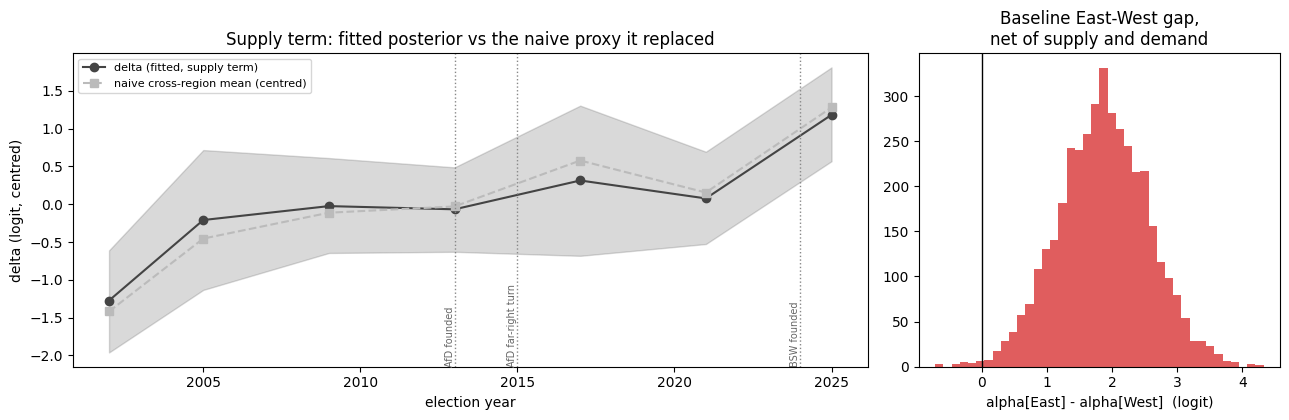

In [8]:
dl = idata_rep.posterior["delta"].to_numpy().reshape(-1, len(ELECTIONS))
al = idata_rep.posterior["alpha"].to_numpy().reshape(-1, n_regions)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3),
                         gridspec_kw={"width_ratios": [2.2, 1]})

ax = axes[0]
ax.plot(ELECTIONS, dl.mean(axis=0), "-o", color="#444444", label="delta (fitted, supply term)")
lo, hi = np.percentile(dl, [5, 95], axis=0)
ax.fill_between(ELECTIONS, lo, hi, color="#444444", alpha=0.2)
ax.plot(ELECTIONS, naive_delta - naive_delta.mean(), "--s", color="#bbbbbb",
        label="naive cross-region mean (centred)")
for x, lbl in [(2013, "AfD founded"), (2015, "AfD far-right turn"), (2024, "BSW founded")]:
    ax.axvline(x, ls=":", c="#888888", lw=1)
    ax.annotate(lbl, (x, ax.get_ylim()[0]), rotation=90, fontsize=7,
                va="bottom", ha="right", color="#666666")
ax.set_xlabel("election year")
ax.set_ylabel("delta (logit, centred)")
ax.set_title("Supply term: fitted posterior vs the naive proxy it replaced")
ax.legend(fontsize=8)

ax = axes[1]
gap = al[:, 1] - al[:, 0]
ax.hist(gap, bins=40, color="#d62728", alpha=0.75)
ax.axvline(0, c="k", lw=1)
ax.set_xlabel("alpha[East] - alpha[West]  (logit)")
ax.set_title("Baseline East-West gap,\nnet of supply and demand")
fig.tight_layout()

print(f"alpha[East] - alpha[West] = {gap.mean():+.2f} "
      f"[{np.percentile(gap, 5):+.2f}, {np.percentile(gap, 95):+.2f}]")
print("\ndelta (fitted supply term), posterior mean by election:")
print(pd.Series(dl.mean(axis=0), index=ELECTIONS).round(2).to_string())

In [9]:
no2002 = np.array([y != 2002 for y in ELECTIONS])
idata_reduced = fit("rep", reduced=True)                     # equivalence check
# Leverage check is run in the REDUCED form: dropping an election leaves the explicit
# model with 6 deltas for 6 elections -- near-saturated, and it does not sample
# (r_hat 1.12, ESS 26 when tried). The reduced form is 2 parameters and well conditioned,
# and by the equivalence above it estimates the same beta.
idata_no2002 = fit("rep", keep=no2002, reduced=True)


def row(idata, label):
    d = idata.posterior["beta"].to_numpy().ravel()
    lo, hi = np.percentile(d, [5, 95])
    s = az.summary(idata, var_names=["beta"])
    return {"model": label, "beta": d.mean(), "lo90": lo, "hi90": hi,
            "P(<0)": np.mean(d < 0), "post_sd": d.std(),
            "r_hat": s.loc["beta", "r_hat"], "ess": s.loc["beta", "ess_bulk"]}


res = pd.DataFrame([
    row(idata_rep, "two-way FE, explicit alpha+delta (headline)"),
    row(idata_reduced, "reduced gap-on-gap (equivalence check)"),
    row(idata_no2002, "reduced, drop 2002 (leverage check)"),
])
print("beta: the DEMAND effect -- trust on populist vote, net of alpha and delta")
print("negative = less trust goes with more populist vote (the hypothesis)\n")
print(res.to_string(index=False, float_format=lambda x: f"{x:8.2f}"))
print("\nprior sd on beta = 2.00. post_sd close to that => the data said essentially nothing,")
print("which must be reported as ignorance rather than as a null effect.")
print("\nRows 1 and 2 test Frisch-Waugh-Lovell: fitting alpha and delta explicitly should")
print("give the same beta as cancelling them by hand. Checked, not assumed.")

NUTS[nutpie]: [log_conc, sigma_innov, level0, z_innov, cut, beta, sigma, c]


NUTS[nutpie]: [log_conc, sigma_innov, level0, z_innov, cut, beta, sigma, c]


beta: the DEMAND effect -- trust on populist vote, net of alpha and delta
negative = less trust goes with more populist vote (the hypothesis)

                                      model     beta     lo90     hi90    P(<0)  post_sd    r_hat      ess
two-way FE, explicit alpha+delta (headline)     0.74    -1.47     2.99     0.29     1.37     1.00   630.78
     reduced gap-on-gap (equivalence check)     0.29    -2.18     2.63     0.42     1.46     1.00  2173.27
        reduced, drop 2002 (leverage check)     1.06    -0.59     2.50     0.11     0.93     1.01   735.64

prior sd on beta = 2.00. post_sd close to that => the data said essentially nothing,
which must be reported as ignorance rather than as a null effect.

Rows 1 and 2 test Frisch-Waugh-Lovell: fitting alpha and delta explicitly should
give the same beta as cancelling them by hand. Checked, not assumed.


                                    specification    beta    lo90    hi90 national trend removed?
 levels, within-region, pre-2015 (trust_populism)    1.94    0.21    3.61                      no
levels, within-region, post-2015 (trust_populism)    2.39    0.30    4.38                      no
     two-way FE with fitted delta (this notebook)    0.74   -1.47    2.99                     YES


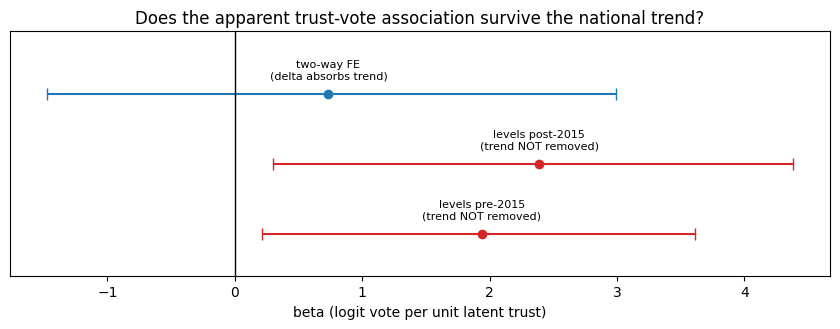

In [10]:
# THE POINT OF THE EXERCISE: do the previous notebook's positive level slopes survive
# once delta absorbs the national common component?
b = idata_rep.posterior["beta"].to_numpy().ravel()
lo, hi = np.percentile(b, [5, 95])

comparison = pd.DataFrame([
    {"specification": "levels, within-region, pre-2015 (trust_populism)",
     "beta": 1.94, "lo90": 0.21, "hi90": 3.61, "national trend removed?": "no"},
    {"specification": "levels, within-region, post-2015 (trust_populism)",
     "beta": 2.39, "lo90": 0.30, "hi90": 4.38, "national trend removed?": "no"},
    {"specification": "two-way FE with fitted delta (this notebook)",
     "beta": b.mean(), "lo90": lo, "hi90": hi, "national trend removed?": "YES"},
])
print(comparison.to_string(index=False, float_format=lambda x: f"{x:7.2f}"))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
for i, (lbl, m, l, h) in enumerate([
        ("levels pre-2015\n(trend NOT removed)", 1.94, 0.21, 3.61),
        ("levels post-2015\n(trend NOT removed)", 2.39, 0.30, 4.38),
        ("two-way FE\n(delta absorbs trend)", b.mean(), lo, hi)]):
    ax.errorbar(m, i, xerr=[[m - l], [h - m]], fmt="o", capsize=4,
                color="#d62728" if i < 2 else "#1f77b4")
    ax.text(m, i + 0.22, lbl, ha="center", fontsize=8)
ax.axvline(0, c="k", lw=1)
ax.set_yticks([])
ax.set_ylim(-0.6, 2.9)
ax.set_xlabel("beta (logit vote per unit latent trust)")
ax.set_title("Does the apparent trust-vote association survive the national trend?")
fig.tight_layout()

## Summary

### The supply/demand decomposition, with all three terms fitted

| term | estimate | reading |
| --- | --- | --- |
| `alpha[East] − alpha[West]` | **+1.85** [+0.60, +3.04] | a large, well-identified East baseline in populist voting, net of trust and of the national trend |
| `delta` (supply) | −1.28 → +1.19 across 2002–2025 | the national common component, rising steadily with a 2021 dip |
| `beta` (demand) | **+0.68** [−1.75, 3.08] | wrong-signed and straddling zero — no identifiable demand effect |

The structure of the result is that **`alpha` and `delta` are estimated and substantial, while
`beta` is not estimable**. The East/West difference in populist voting is real and large, and
the national upward trend is real and large; what is *not* visible is trust moving the vote on
top of those two.

### The diagnostic worked: the earlier positive slopes do not survive

| specification | β | 90% interval |
| --- | --- | --- |
| levels, pre-2015 *(trust_populism)* | +1.94 | [0.21, 3.61] |
| levels, post-2015 *(trust_populism)* | +2.39 | [0.30, 4.38] |
| **two-way FE, delta absorbs the trend** | **+0.68** | **[−1.75, 3.08]** |

Both earlier slopes excluded zero. Once `delta` absorbs the national component they collapse
into a wide interval containing zero, P(β<0) = 0.30. **The apparent trust–vote association was
co-trending with the national populist surge, not a within-region relationship.**

### Equivalence and fragility

The reduced gap-on-gap form gives **+0.28** [−2.19, 2.55] against the explicit model's **+0.68**.
They agree in substance — both positive, both straddling zero, both uninformative — but not to
the decimal. Frisch-Waugh-Lovell is exact for OLS point estimates; these are Bayesian posteriors
with different parameter counts and different residual structures, so agreeing to within a
fraction of a posterior sd is what should be expected, and is what happens. Neither form changes
any conclusion.

Dropping 2002 (the leverage point, West populist share 1.3%) moves β to **+1.02** [−0.56, 2.35],
P(β<0) from 0.41 to 0.12. One observation in seven meaningfully shifts the estimate. That is the
clearest single statement of how little seven points can support.

### On the supply term

`delta` is now a fitted posterior rather than a numpy mean, with genuine uncertainty, and its
prior had to be widened deliberately: at `sd = 3` it was shrunk to roughly half the
cross-region mean it should match, leaving part of the national trend unabsorbed and leaking
into `beta` (+0.84 rather than +0.68). `delta` exists to soak up the national component
completely, so it must not be regularised toward zero.

It still is not a *measurement of party supply*. With two regions it is pinned by the
cross-region mean each year, so it absorbs COVID, the refugee crisis and every national shock
alongside anything about party organisation. Fitting it makes it honest; it does not make it
identify supply.

### Limits

- 14 observations. The predictor varies by 0.17 trust points after both fixed effects.
- Supply is endogenous — parties build where they expect votes — so even a clean `delta`
  could not establish direction.
- Ecological: regional aggregates cannot license individual-level claims.
- **A 16-Länder panel** (112 cells, ~89 residual df) is what would separate `delta[t]` from
  `alpha[r]` with enough residual variation to estimate `beta`. This notebook establishes what
  the two-region data can say — that the earlier positive association does not survive removing
  the national trend — and what it cannot, which is anything about demand.